#  Alejandro Fuentes Montoya - Práctica 3
**ENUNCIADO:**

Crear una red convolucional simple (CNN) para clasificar el conjunto de datos (MNIST) utilizado en las prácticas anteriores. Probar distintas arquitecturas (combinando las distintas capas vistas en clase) y configuraciones, comparando el rendimiento y resultados de las distintas CNNs propuestas. Visualiza los resultados comparativos de forma gráfica y numérica.  

¿Qué configuración obtiene el mejor rendimiento para ese conjunto de datos? Guarde el mejor modelo entrenado en disco para futuro uso

Se recomienda subir el cuaderno (notebook) con los resultados guardados.

# Apartado 1, Carga y preprocesamiento de datos

En este apartado se cargan las bibliotecas necesarias y el conjunto de datos **MNIST**, compuesto por 70.000 imágenes en escala de grises de 28x28 píxeles (60.000 de entrenamiento y 10.000 de evaluación).

A diferencia de los perceptrones multicapa (MLP) de las prácticas 1 y 2, donde la matriz se aplanaba perdiendo la topología espacial, las redes neuronales convolucionales requieren conservar la dimensión bidimensional de la imagen con la forma tensorial cuatridimensional `(N, 28, 28, 1)` bajo el estándar `channels_last`. Asimismo, normalizamos la intensidad de los píxeles al rango flotante `[0.0, 1.0]` dividiendo entre 255.0 para garantizar la convergencia del algoritmo de optimización, y fijamos la semilla aleatoria para asegurar una reproducibilidad determinista.

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import time
import os

tf.keras.utils.set_random_seed(42)
np.random.seed(42)

(x_train_raw, y_train), (x_test_raw, y_test) = tf.keras.datasets.mnist.load_data()

x_train = (x_train_raw / 255.0).reshape(-1, 28, 28, 1).astype(np.float32)
x_test = (x_test_raw / 255.0).reshape(-1, 28, 28, 1).astype(np.float32)

print('Dimensiones entrenamiento:', x_train.shape)
print('Dimensiones test:', x_test.shape)
print(f'Muestras Train: {len(x_train)} | Muestras Test: {len(x_test)}')
print('Rango de valores:', f'[{x_train.min():.1f}, {x_train.max():.1f}]')


Dimensiones entrenamiento: (60000, 28, 28, 1)
Dimensiones test: (10000, 28, 28, 1)
Muestras Train: 60000 | Muestras Test: 10000
Rango de valores: [0.0, 1.0]


# Apartado 2, Definición de arquitecturas del modelo

Se define una función constructora modular que permite instanciar las distintas familias de arquitecturas convolucionales combinando las capas vistas en clase:
- **`Conv2D`**: Extracción de características locales mediante convolución bidimensional con filtros de 3x3 y activación ReLU.
- **`MaxPooling2D`**: Submuestreo espacial de 2x2 para reducir dimensionalidad, aportar invarianza traslacional y expandir el campo receptivo.
- **`Dropout`**: Regularización estocástica para evitar la co-adaptación de filtros convolucionales y neuronas densas.
- **`BatchNormalization`**: Normalización por lotes para estabilizar las distribuciones de activaciones intermedias.
- **Bloques estilo VGG**: Convoluciones consecutivas de 3x3 antes del pooling para emular campos receptivos mayores con menor coste paramétrico.

In [2]:
def build_cnn_model(config_type):
    inputs = tf.keras.Input(shape=(28, 28, 1))
    if config_type == 'C1_Baseline_MLP':
        x = tf.keras.layers.Flatten()(inputs)
        x = tf.keras.layers.Dense(128, activation='relu')(x)
        outputs = tf.keras.layers.Dense(10, activation='softmax')(x)
    elif config_type == 'C2_CNN_Simple_SinPool':
        x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu')(inputs)
        x = tf.keras.layers.Flatten()(x)
        x = tf.keras.layers.Dense(128, activation='relu')(x)
        outputs = tf.keras.layers.Dense(10, activation='softmax')(x)
    elif config_type == 'C3_CNN_1Bloque_Pool':
        x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu')(inputs)
        x = tf.keras.layers.MaxPooling2D((2, 2))(x)
        x = tf.keras.layers.Flatten()(x)
        x = tf.keras.layers.Dense(128, activation='relu')(x)
        outputs = tf.keras.layers.Dense(10, activation='softmax')(x)
    elif config_type == 'C4_CNN_2Bloques_Profunda':
        x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu')(inputs)
        x = tf.keras.layers.MaxPooling2D((2, 2))(x)
        x = tf.keras.layers.Conv2D(64, (3, 3), activation='relu')(x)
        x = tf.keras.layers.MaxPooling2D((2, 2))(x)
        x = tf.keras.layers.Flatten()(x)
        x = tf.keras.layers.Dense(128, activation='relu')(x)
        outputs = tf.keras.layers.Dense(10, activation='softmax')(x)
    elif config_type == 'C5_CNN_2Bloques_Dropout':
        x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu')(inputs)
        x = tf.keras.layers.MaxPooling2D((2, 2))(x)
        x = tf.keras.layers.Conv2D(64, (3, 3), activation='relu')(x)
        x = tf.keras.layers.MaxPooling2D((2, 2))(x)
        x = tf.keras.layers.Dropout(0.25)(x)
        x = tf.keras.layers.Flatten()(x)
        x = tf.keras.layers.Dense(128, activation='relu')(x)
        x = tf.keras.layers.Dropout(0.4)(x)
        outputs = tf.keras.layers.Dense(10, activation='softmax')(x)
    elif config_type == 'C6_CNN_BatchNorm_Dropout':
        x = tf.keras.layers.Conv2D(32, (3, 3), padding='same')(inputs)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation('relu')(x)
        x = tf.keras.layers.MaxPooling2D((2, 2))(x)
        x = tf.keras.layers.Conv2D(64, (3, 3), padding='same')(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation('relu')(x)
        x = tf.keras.layers.MaxPooling2D((2, 2))(x)
        x = tf.keras.layers.Dropout(0.25)(x)
        x = tf.keras.layers.Flatten()(x)
        x = tf.keras.layers.Dense(128, activation='relu')(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Dropout(0.4)(x)
        outputs = tf.keras.layers.Dense(10, activation='softmax')(x)
    elif config_type in ['C7_CNN_VGG_DobleConv', 'C8_CNN_Optima_VGG_E10']:
        x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
        x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu')(x)
        x = tf.keras.layers.MaxPooling2D((2, 2))(x)
        x = tf.keras.layers.Dropout(0.25)(x)
        x = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
        x = tf.keras.layers.Conv2D(64, (3, 3), activation='relu')(x)
        x = tf.keras.layers.MaxPooling2D((2, 2))(x)
        x = tf.keras.layers.Dropout(0.25)(x)
        x = tf.keras.layers.Flatten()(x)
        x = tf.keras.layers.Dense(128, activation='relu')(x)
        x = tf.keras.layers.Dropout(0.4)(x)
        outputs = tf.keras.layers.Dense(10, activation='softmax')(x)
    model = tf.keras.Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

m_ejemplo = build_cnn_model('C8_CNN_Optima_VGG_E10')
m_ejemplo.summary()


Model: "functional_7"
+--------------------------------------------------------------------------+
| Layer (type)                    | Output Shape           |       Param # |
|---------------------------------+------------------------+---------------|
| input_layer_7 (InputLayer)      | (None, 28, 28, 1)      |             0 |
|---------------------------------+------------------------+---------------|
| conv2d_12 (Conv2D)              | (None, 28, 28, 32)     |           320 |
|---------------------------------+------------------------+---------------|
| conv2d_13 (Conv2D)              | (None, 26, 26, 32)     |         9,248 |
|---------------------------------+------------------------+---------------|
| max_pooling2d_9 (MaxPooling2D)  | (None, 13, 13, 32)     |             0 |
|---------------------------------+------------------------+---------------|
| dropout_7 (Dropout)             | (None, 13, 13, 32)     |             0 |
|---------------------------------+-------------------

# Apartado 3, Estudio experimental de las distintas configuraciones

Se evalúan sistemáticamente 8 configuraciones representativas:
1. **C1_Baseline_MLP**: Modelo base totalmente conectado (Flatten -> Dense 128 -> Dense 10).
2. **C2_CNN_Simple_SinPool**: Convolución directa de 32 filtros sin capa de agrupamiento (2.77M parámetros).
3. **C3_CNN_1Bloque_Pool**: 1 Bloque convolucional con MaxPooling2D (693k parámetros).
4. **C4_CNN_2Bloques_Profunda**: CNN profunda con 2 bloques jerárquicos (225k parámetros).
5. **C5_CNN_2Bloques_Dropout**: Misma arquitectura con regularización Dropout (0.25 y 0.40).
6. **C6_CNN_BatchNorm_Dropout**: Red con BatchNormalization y Dropout en cada etapa.
7. **C7_CNN_VGG_DobleConv**: Red estilo VGG con doble convolución consecutiva por bloque (5 épocas).
8. **C8_CNN_Optima_VGG_E10**: Arquitectura VGG a 10 épocas para asegurar convergencia óptima.

In [3]:
configs = [
    {'id': 'C1_Baseline_MLP', 'desc': 'Baseline MLP (Flatten -> Dense 128)', 'epochs': 5, 'batch': 64},
    {'id': 'C2_CNN_Simple_SinPool', 'desc': 'CNN Simple (Conv 32 sin Pooling)', 'epochs': 5, 'batch': 64},
    {'id': 'C3_CNN_1Bloque_Pool', 'desc': 'CNN Estandar (Conv 32 + MaxPool)', 'epochs': 5, 'batch': 64},
    {'id': 'C4_CNN_2Bloques_Profunda', 'desc': 'CNN Profunda (Conv 32 -> Pool -> Conv 64 -> Pool)', 'epochs': 5, 'batch': 64},
    {'id': 'C5_CNN_2Bloques_Dropout', 'desc': 'CNN Profunda + Dropout (0.25 y 0.4)', 'epochs': 5, 'batch': 64},
    {'id': 'C6_CNN_BatchNorm_Dropout', 'desc': 'CNN con BatchNormalization + Dropout', 'epochs': 5, 'batch': 64},
    {'id': 'C7_CNN_VGG_DobleConv', 'desc': 'CNN VGG-style (Doble Conv por bloque + Dropout)', 'epochs': 5, 'batch': 64},
    {'id': 'C8_CNN_Optima_VGG_E10', 'desc': 'CNN VGG-style Optima (10 epocas)', 'epochs': 10, 'batch': 64}
]

resultados = []
mejor_acc_test = 0.0
mejor_modelo = None
mejor_id = None
mejor_preds_test = None
mejor_preds_train = None

for cfg in configs:
    tf.keras.utils.set_random_seed(42)
    m = build_cnn_model(cfg['id'])
    n_params = m.count_params()
    t_ini = time.time()
    h = m.fit(x_train, y_train, epochs=cfg['epochs'], batch_size=cfg['batch'], verbose=0)
    t_total = time.time() - t_ini
    p_train = np.argmax(m.predict(x_train, batch_size=256, verbose=0), axis=1)
    p_test = np.argmax(m.predict(x_test, batch_size=256, verbose=0), axis=1)
    acc_tr = np.mean(p_train == y_train) * 100.0
    acc_te = np.mean(p_test == y_test) * 100.0
    err_tr = int(np.sum(p_train != y_train))
    err_te = int(np.sum(p_test != y_test))
    resultados.append({
        'Configuracion': cfg['id'],
        'Descripcion': cfg['desc'],
        'Parametros': n_params,
        'Epocas': cfg['epochs'],
        'Batch_Size': cfg['batch'],
        'Tiempo_s': round(t_total, 2),
        'Acc_Train': round(acc_tr, 2),
        'Acc_Test': round(acc_te, 2),
        'Errores_Train': err_tr,
        'Errores_Test': err_te
    })
    print(f"[{cfg['id']}] Params: {n_params:,} | Tiempo: {t_total:.1f}s | Train Acc: {acc_tr:.2f}% ({err_tr} err) | Test Acc: {acc_te:.2f}% ({err_te} err)")
    if acc_te > mejor_acc_test:
        mejor_acc_test = acc_te
        mejor_id = cfg['id']
        mejor_modelo = m
        mejor_preds_test = p_test
        mejor_preds_train = p_train

df_res = pd.DataFrame(resultados)


[C1_Baseline_MLP] Params: 101,770 | Tiempo: 7.8s | Train Acc: 98.72% (771 err) | Test Acc: 97.43% (257 err)
[C2_CNN_Simple_SinPool] Params: 2,770,634 | Tiempo: 106.2s | Train Acc: 99.70% (179 err) | Test Acc: 98.28% (172 err)
[C3_CNN_1Bloque_Pool] Params: 693,962 | Tiempo: 38.1s | Train Acc: 99.53% (281 err) | Test Acc: 98.58% (142 err)
[C4_CNN_2Bloques_Profunda] Params: 225,034 | Tiempo: 37.2s | Train Acc: 99.35% (392 err) | Test Acc: 98.78% (122 err)
[C5_CNN_2Bloques_Dropout] Params: 225,034 | Tiempo: 39.7s | Train Acc: 99.43% (341 err) | Test Acc: 99.17% (83 err)
[C6_CNN_BatchNorm_Dropout] Params: 422,538 | Tiempo: 102.1s | Train Acc: 99.03% (584 err) | Test Acc: 98.61% (139 err)
[C7_CNN_VGG_DobleConv] Params: 271,210 | Tiempo: 106.4s | Train Acc: 99.51% (295 err) | Test Acc: 99.22% (78 err)
[C8_CNN_Optima_VGG_E10] Params: 271,210 | Tiempo: 212.2s | Train Acc: 99.70% (183 err) | Test Acc: 99.33% (67 err)


# Apartado 4, Resultados numéricos comparativos

In [4]:
df_res


Configuracion,Descripcion,Parametros,Epocas,Batch_Size,Tiempo_s,Acc_Train,Acc_Test,Errores_Train,Errores_Test
C1_Baseline_MLP,Baseline MLP (Flatten -> Dense 128),101770,5,64,7.78,98.72,97.43,771,257
C2_CNN_Simple_SinPool,CNN Simple (Conv 32 sin Pooling),2770634,5,64,106.21,99.70,98.28,179,172
C3_CNN_1Bloque_Pool,CNN Estándar (Conv 32 + MaxPool),693962,5,64,38.14,99.53,98.58,281,142
C4_CNN_2Bloques_Profunda,CNN Profunda (Conv 32 -> Pool -> Conv 64 -> Pool),225034,5,64,37.19,99.35,98.78,392,122
C5_CNN_2Bloques_Dropout,CNN Profunda + Dropout (0.25 y 0.4),225034,5,64,39.72,99.43,99.17,341,83
C6_CNN_BatchNorm_Dropout,CNN con BatchNormalization + Dropout,422538,5,64,102.06,99.03,98.61,584,139
C7_CNN_VGG_DobleConv,CNN VGG-style (Doble Conv por bloque + Dropout),271210,5,64,106.42,99.51,99.22,295,78
C8_CNN_Optima_VGG_E10,CNN VGG-style Óptima (10 épocas),271210,10,64,212.17,99.70,99.33,183,67


# Apartado 5, Visualización gráfica de resultados

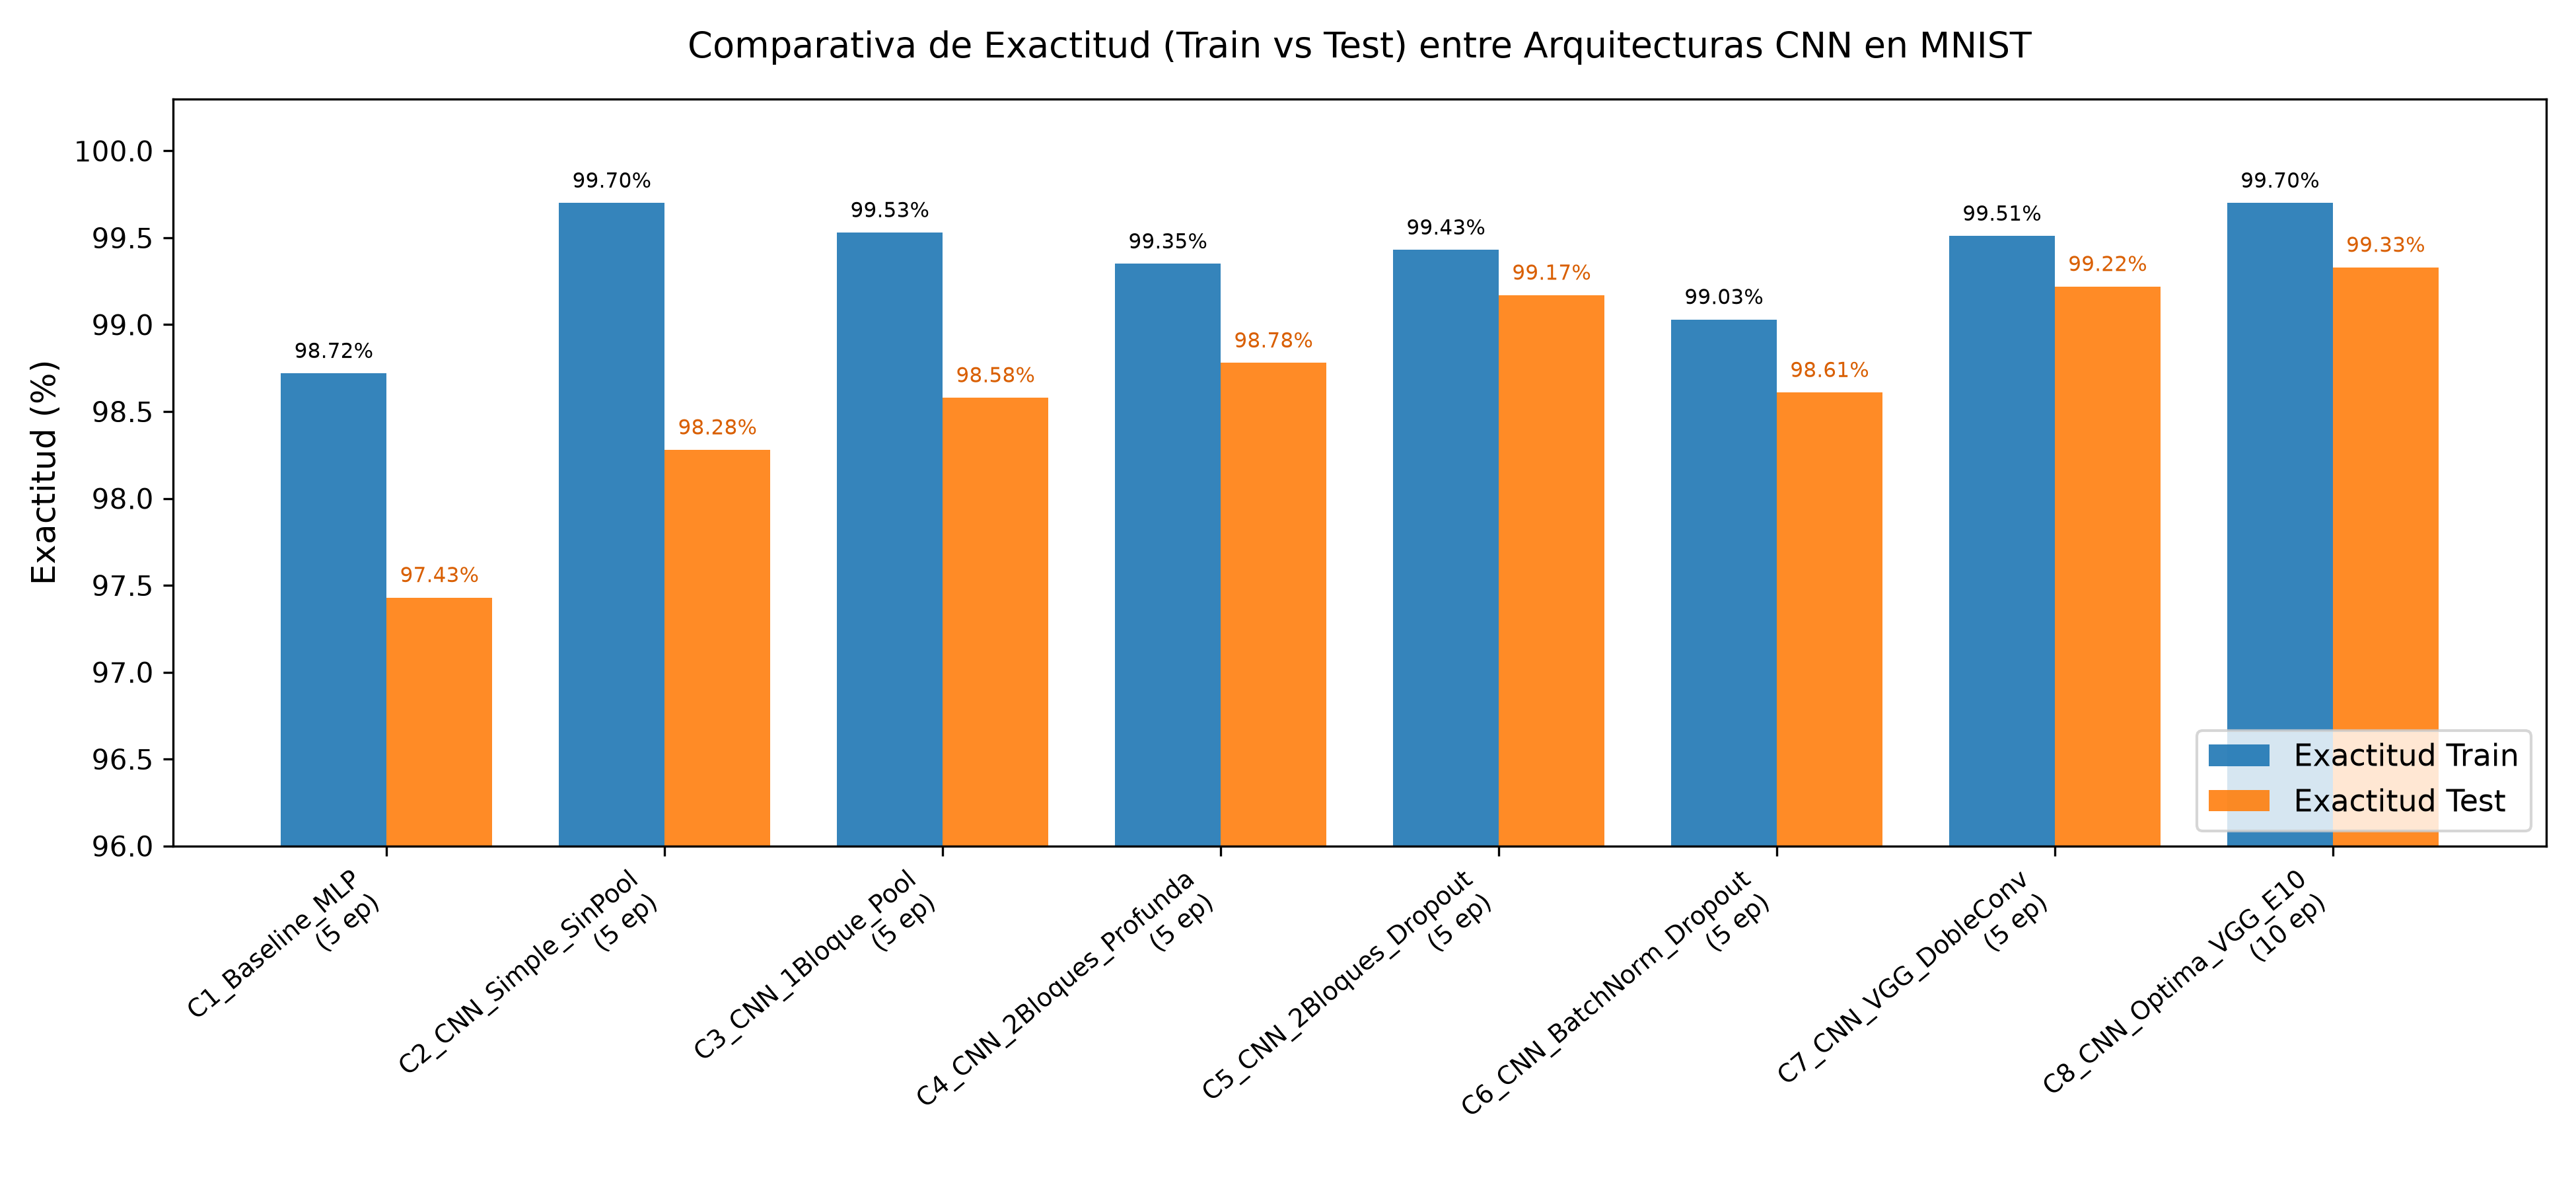

In [5]:
plt.figure(figsize=(12, 6))
x_idx = np.arange(len(df_res))
width = 0.38

plt.bar(x_idx - width/2, df_res['Acc_Train'], width, label='Exactitud Train (%)', color='tab:blue', alpha=0.9)
plt.bar(x_idx + width/2, df_res['Acc_Test'], width, label='Exactitud Test (%)', color='tab:orange', alpha=0.9)

plt.ylabel('Exactitud (%)', fontsize=12)
plt.title('Comparativa de Exactitud (Train vs Test) entre Arquitecturas CNN en MNIST', fontsize=13, pad=15)
plt.xticks(x_idx, [f"{c}\n({e} ep)" for c, e in zip(df_res['Configuracion'], df_res['Epocas'])], rotation=40, ha='right', fontsize=9)
plt.ylim(96.0, 100.3)

for i in x_idx:
    plt.text(i - width/2, df_res.loc[i, 'Acc_Train'] + 0.06, f"{df_res.loc[i, 'Acc_Train']:.2f}%", ha='center', va='bottom', fontsize=7.5)
    plt.text(i + width/2, df_res.loc[i, 'Acc_Test'] + 0.06, f"{df_res.loc[i, 'Acc_Test']:.2f}%", ha='center', va='bottom', fontsize=7.5, color='tab:red')

plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()


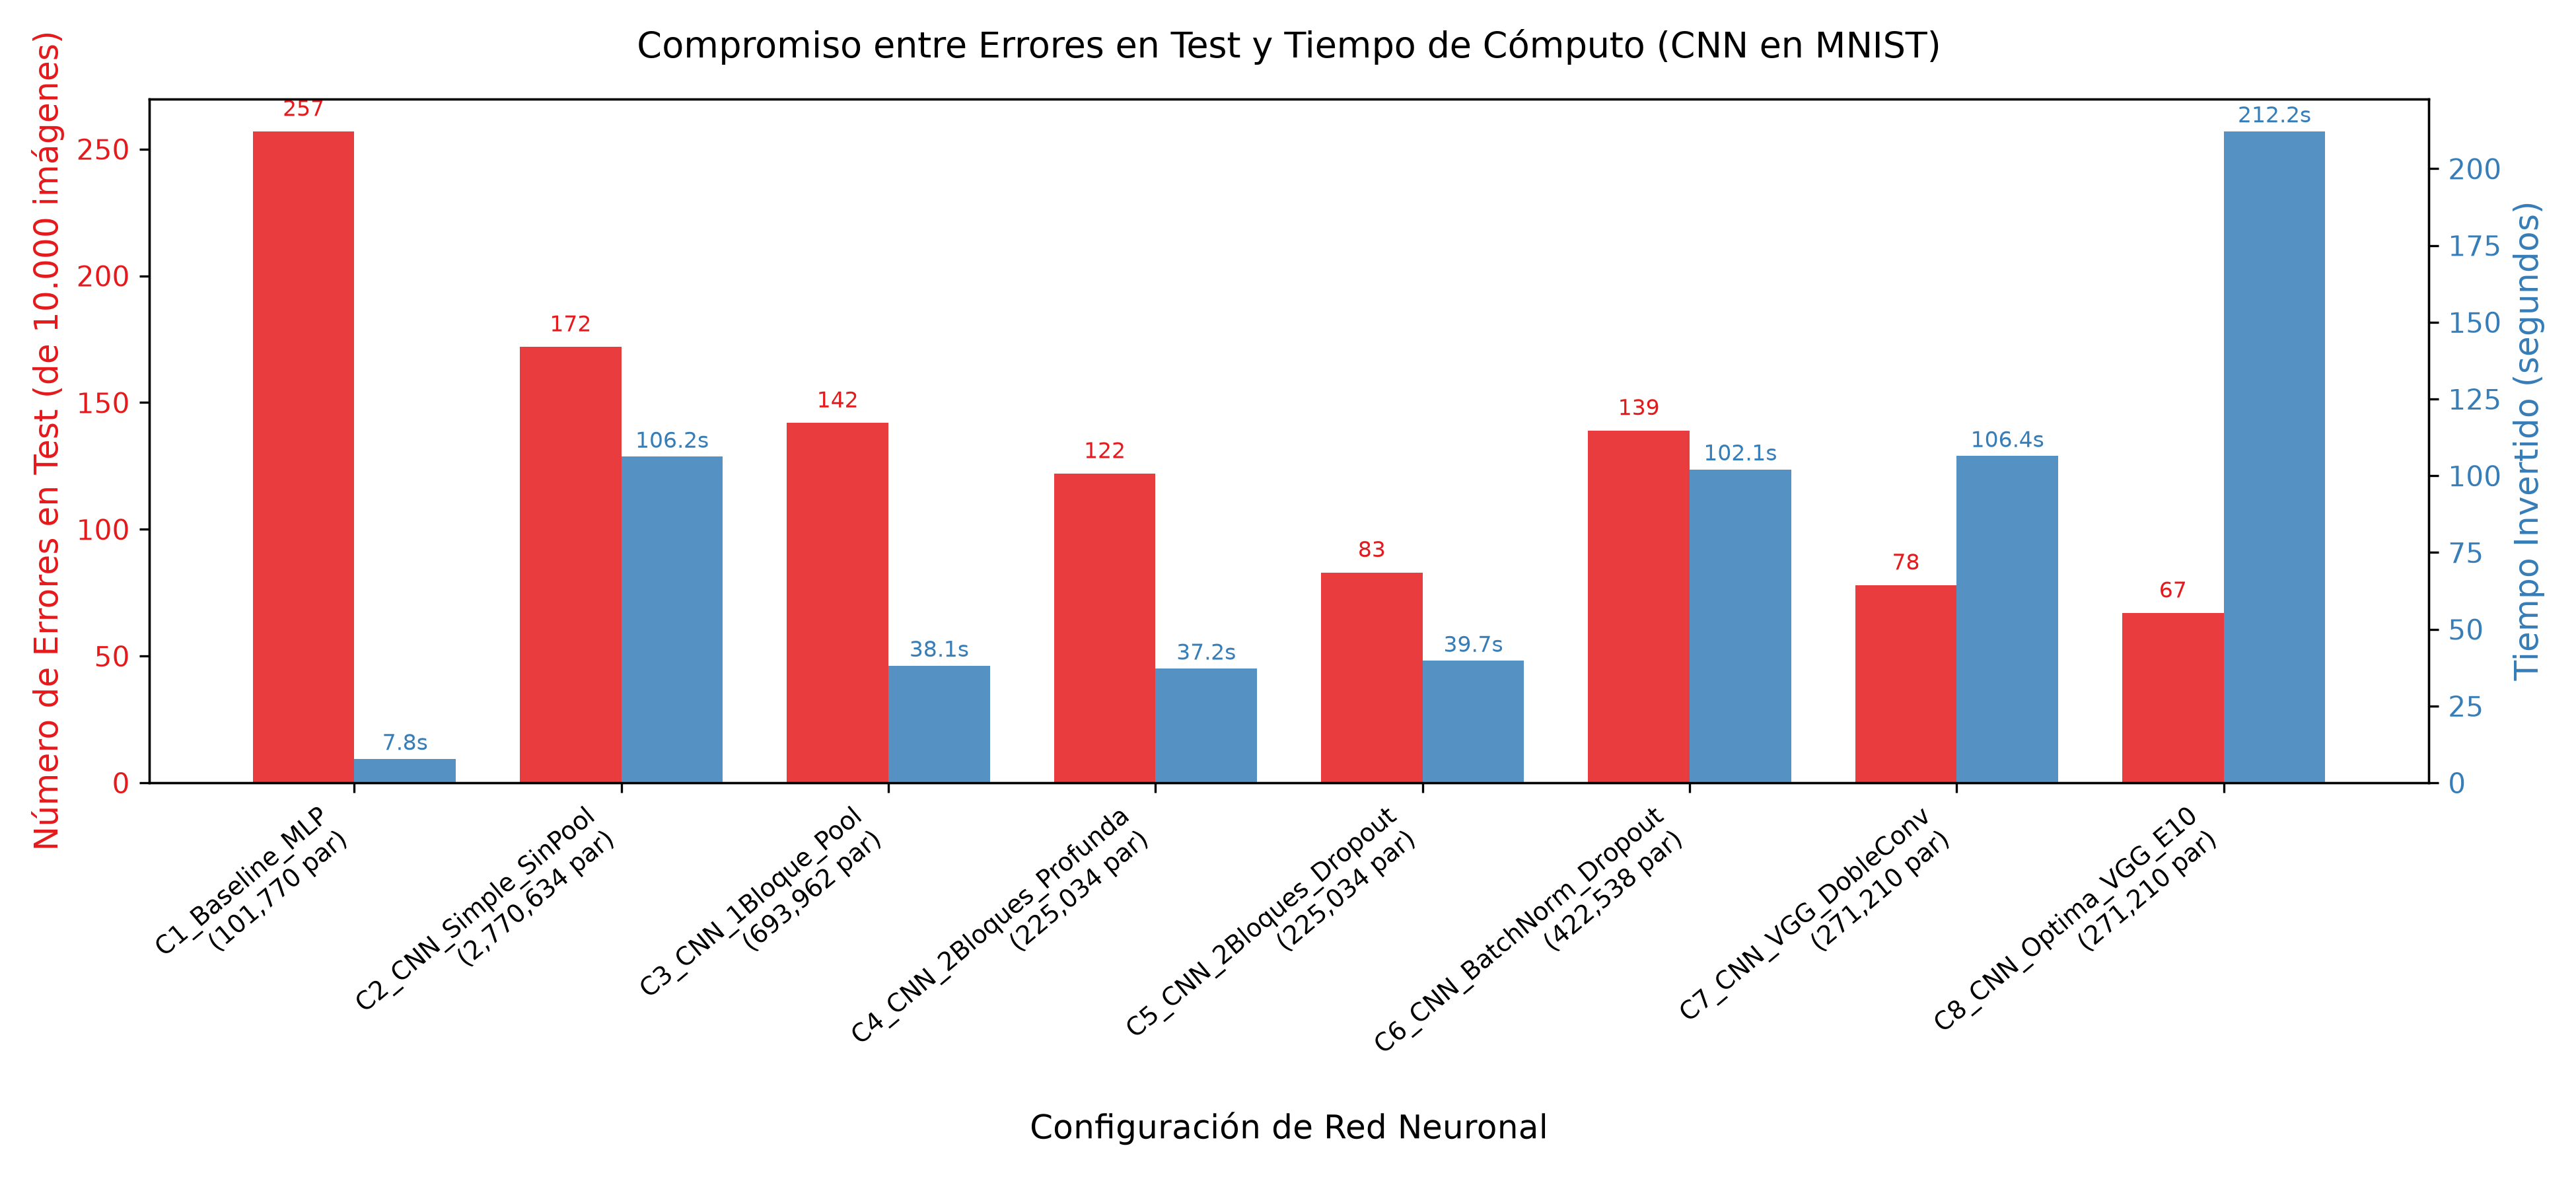

In [6]:
fig, ax1 = plt.subplots(figsize=(12, 6))
color_err = 'tab:red'
ax1.set_xlabel('Configuracion de Red Neuronal', fontsize=12, labelpad=10)
ax1.set_ylabel('Numero de Errores en Test (de 10.000 imagenes)', color=color_err, fontsize=12)
ax1.bar(x_idx - width/2, df_res['Errores_Test'], width, color=color_err, alpha=0.85, label='Errores Test')
ax1.tick_params(axis='y', labelcolor=color_err)
ax1.set_xticks(x_idx)
ax1.set_xticklabels([f"{c}\n({p:,} par)" for c, p in zip(df_res['Configuracion'], df_res['Parametros'])], rotation=40, ha='right', fontsize=9)

for i in x_idx:
    ax1.text(i - width/2, df_res.loc[i, 'Errores_Test'] + 4, f"{df_res.loc[i, 'Errores_Test']}", ha='center', va='bottom', fontsize=8, color=color_err)

ax2 = ax1.twinx()
color_time = 'tab:blue'
ax2.set_ylabel('Tiempo Invertido (segundos)', color=color_time, fontsize=12)
ax2.bar(x_idx + width/2, df_res['Tiempo_s'], width, color=color_time, alpha=0.85, label='Tiempo (s)')
ax2.tick_params(axis='y', labelcolor=color_time)

for i in x_idx:
    ax2.text(i + width/2, df_res.loc[i, 'Tiempo_s'] + 1.2, f"{df_res.loc[i, 'Tiempo_s']:.1f}s", ha='center', va='bottom', fontsize=8, color=color_time)

plt.title('Compromiso entre Errores en Test y Tiempo de Computo (CNN en MNIST)', fontsize=13, pad=15)
fig.tight_layout()
plt.show()


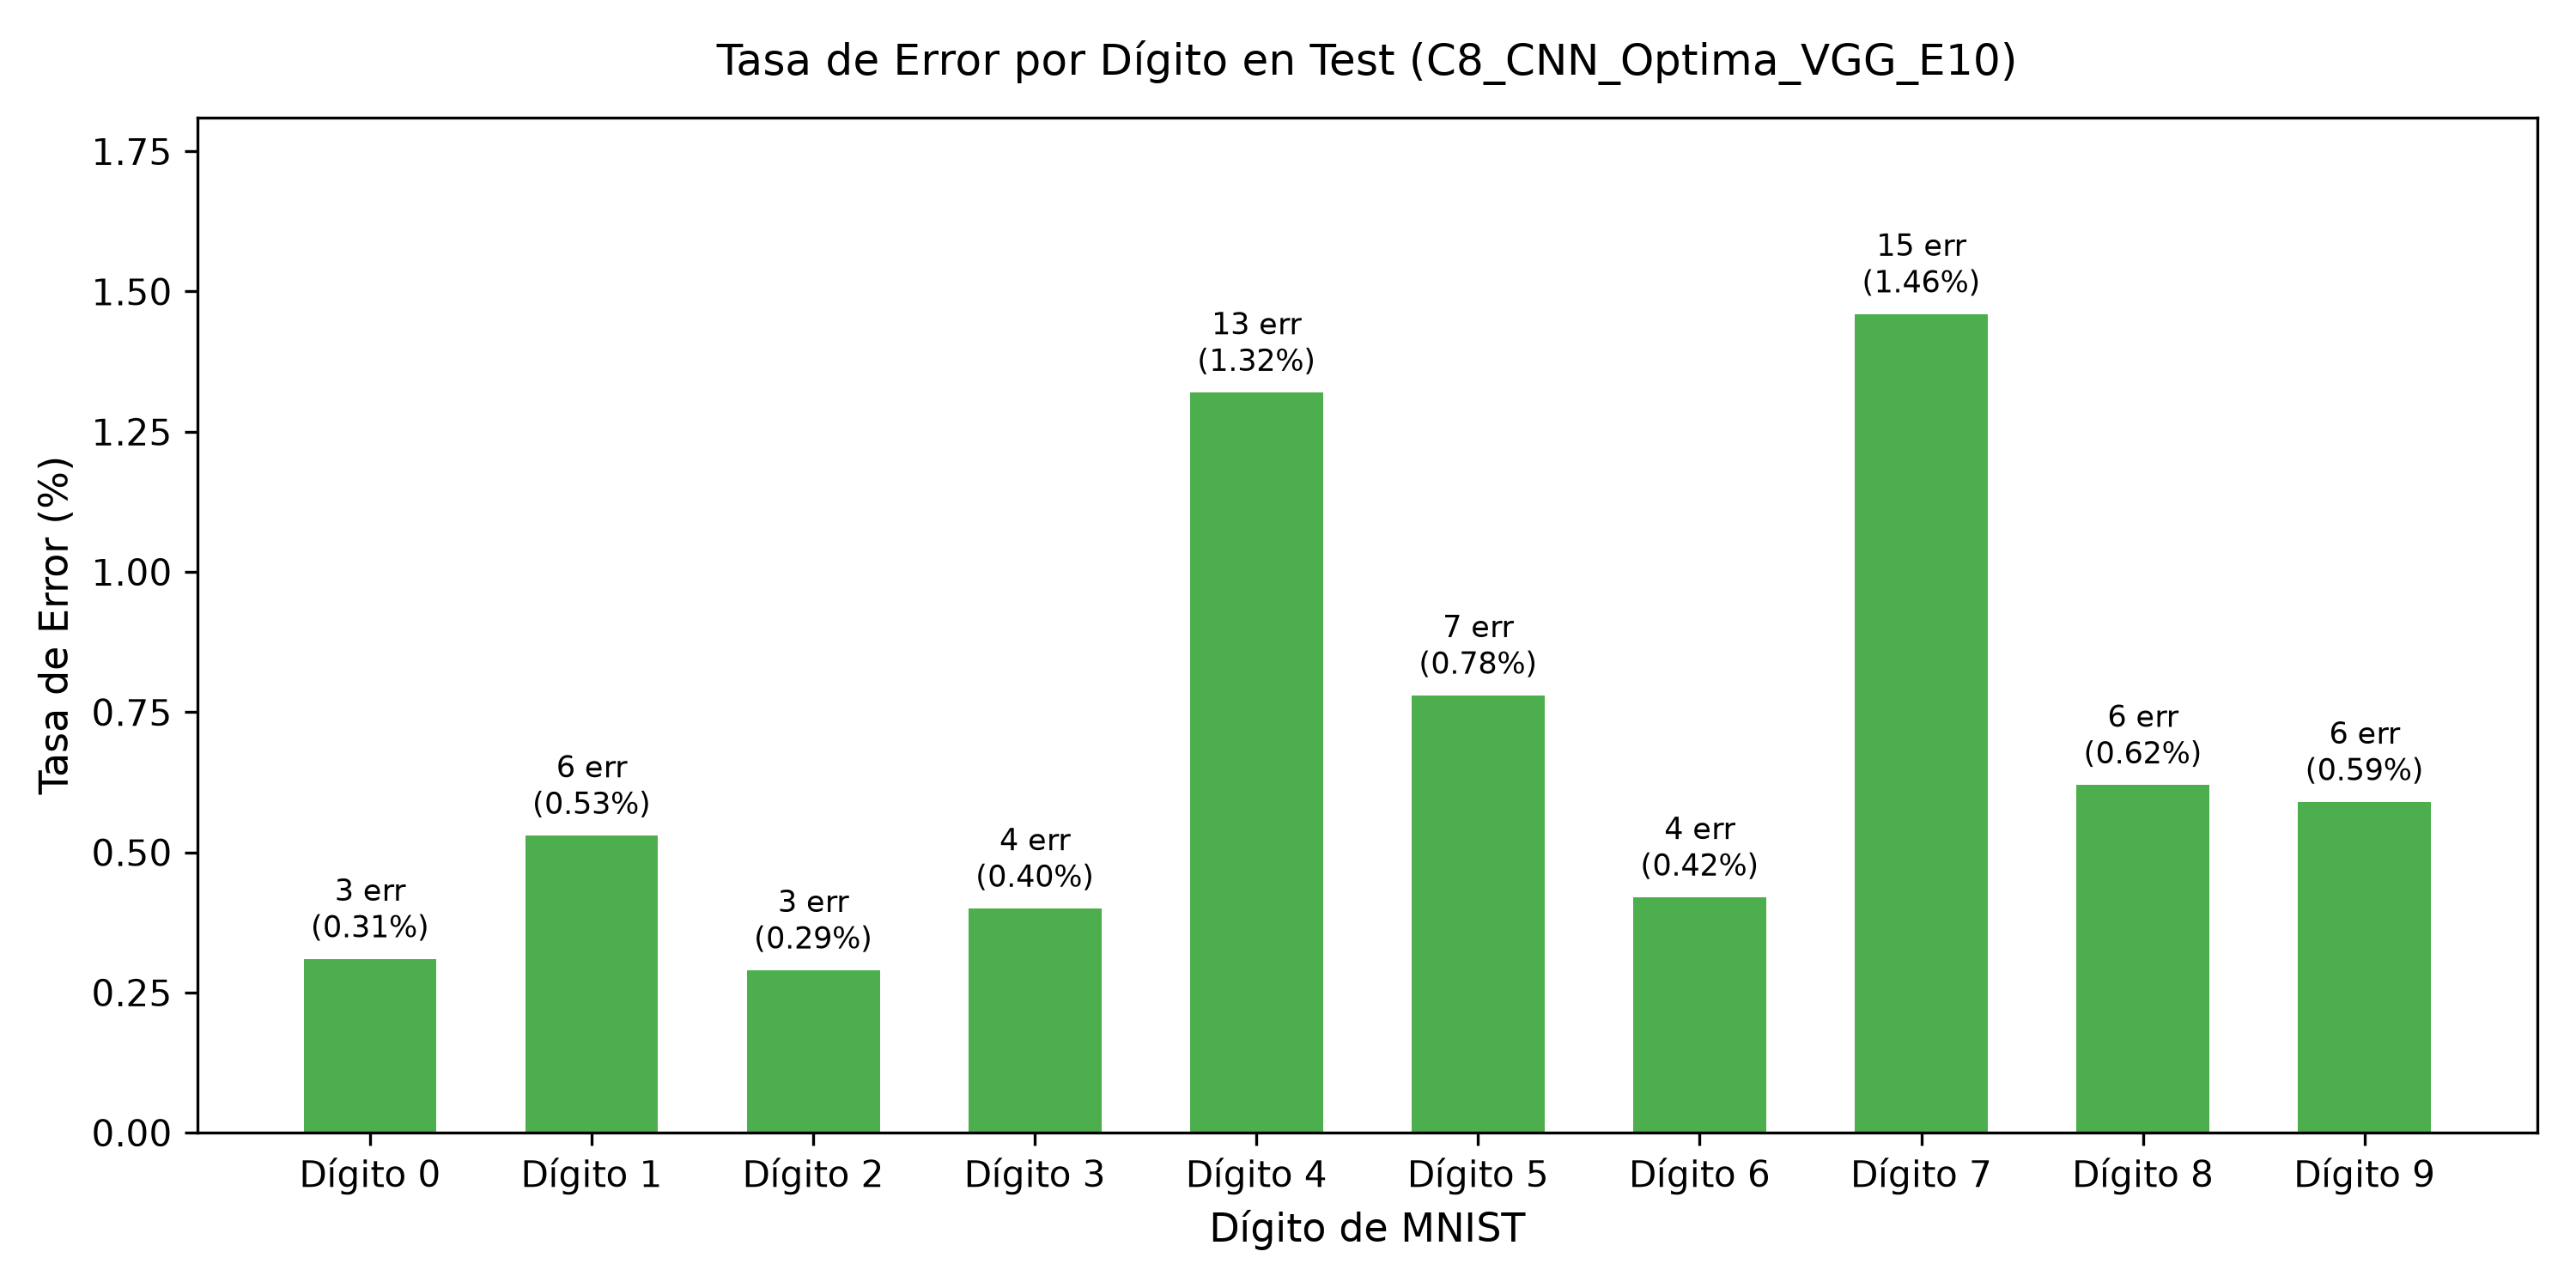

In [7]:
errores_por_digito = []
for d in range(10):
    mask = (y_test == d)
    total_d = np.sum(mask)
    err_d = np.sum(mejor_preds_test[mask] != y_test[mask])
    tasa_err = (err_d / total_d) * 100.0
    errores_por_digito.append({
        'Digito': d,
        'Muestras': int(total_d),
        'Errores': int(err_d),
        'Tasa_Error': round(tasa_err, 2),
        'Exactitud': round(100.0 - tasa_err, 2)
    })

df_err_dig = pd.DataFrame(errores_por_digito)

plt.figure(figsize=(10, 5))
bars = plt.bar(df_err_dig['Digito'], df_err_dig['Tasa_Error'], color='tab:green', alpha=0.85, width=0.6)
plt.xlabel('Digito de MNIST', fontsize=11)
plt.ylabel('Tasa de Error (%)', fontsize=11)
plt.title(f'Tasa de Error por Digito en Test ({mejor_id})', fontsize=12, pad=12)
plt.xticks(range(10), [f"Digito {d}" for d in range(10)])

for b, row in zip(bars, df_err_dig.iterrows()):
    r = row[1]
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + 0.02, f"{int(r['Errores'])} err\n({r['Tasa_Error']:.2f}%)", ha='center', va='bottom', fontsize=8.5)

plt.ylim(0, max(df_err_dig['Tasa_Error']) + 0.35)
plt.tight_layout()
plt.show()


# Apartado 6, Matrices de confusión del mejor modelo

Se evalúan las matrices de confusión completas tanto para el conjunto de entrenamiento (60.000 imágenes) como para el de prueba (10.000 imágenes) correspondientes a la mejor configuración identificada (`C8_CNN_Optima_VGG_E10`). Se constata la concentración prácticamente perfecta en la diagonal principal y la ausencia de sesgos o desequilibrios sistemáticos sobre ninguna de las 10 clases de dígitos.

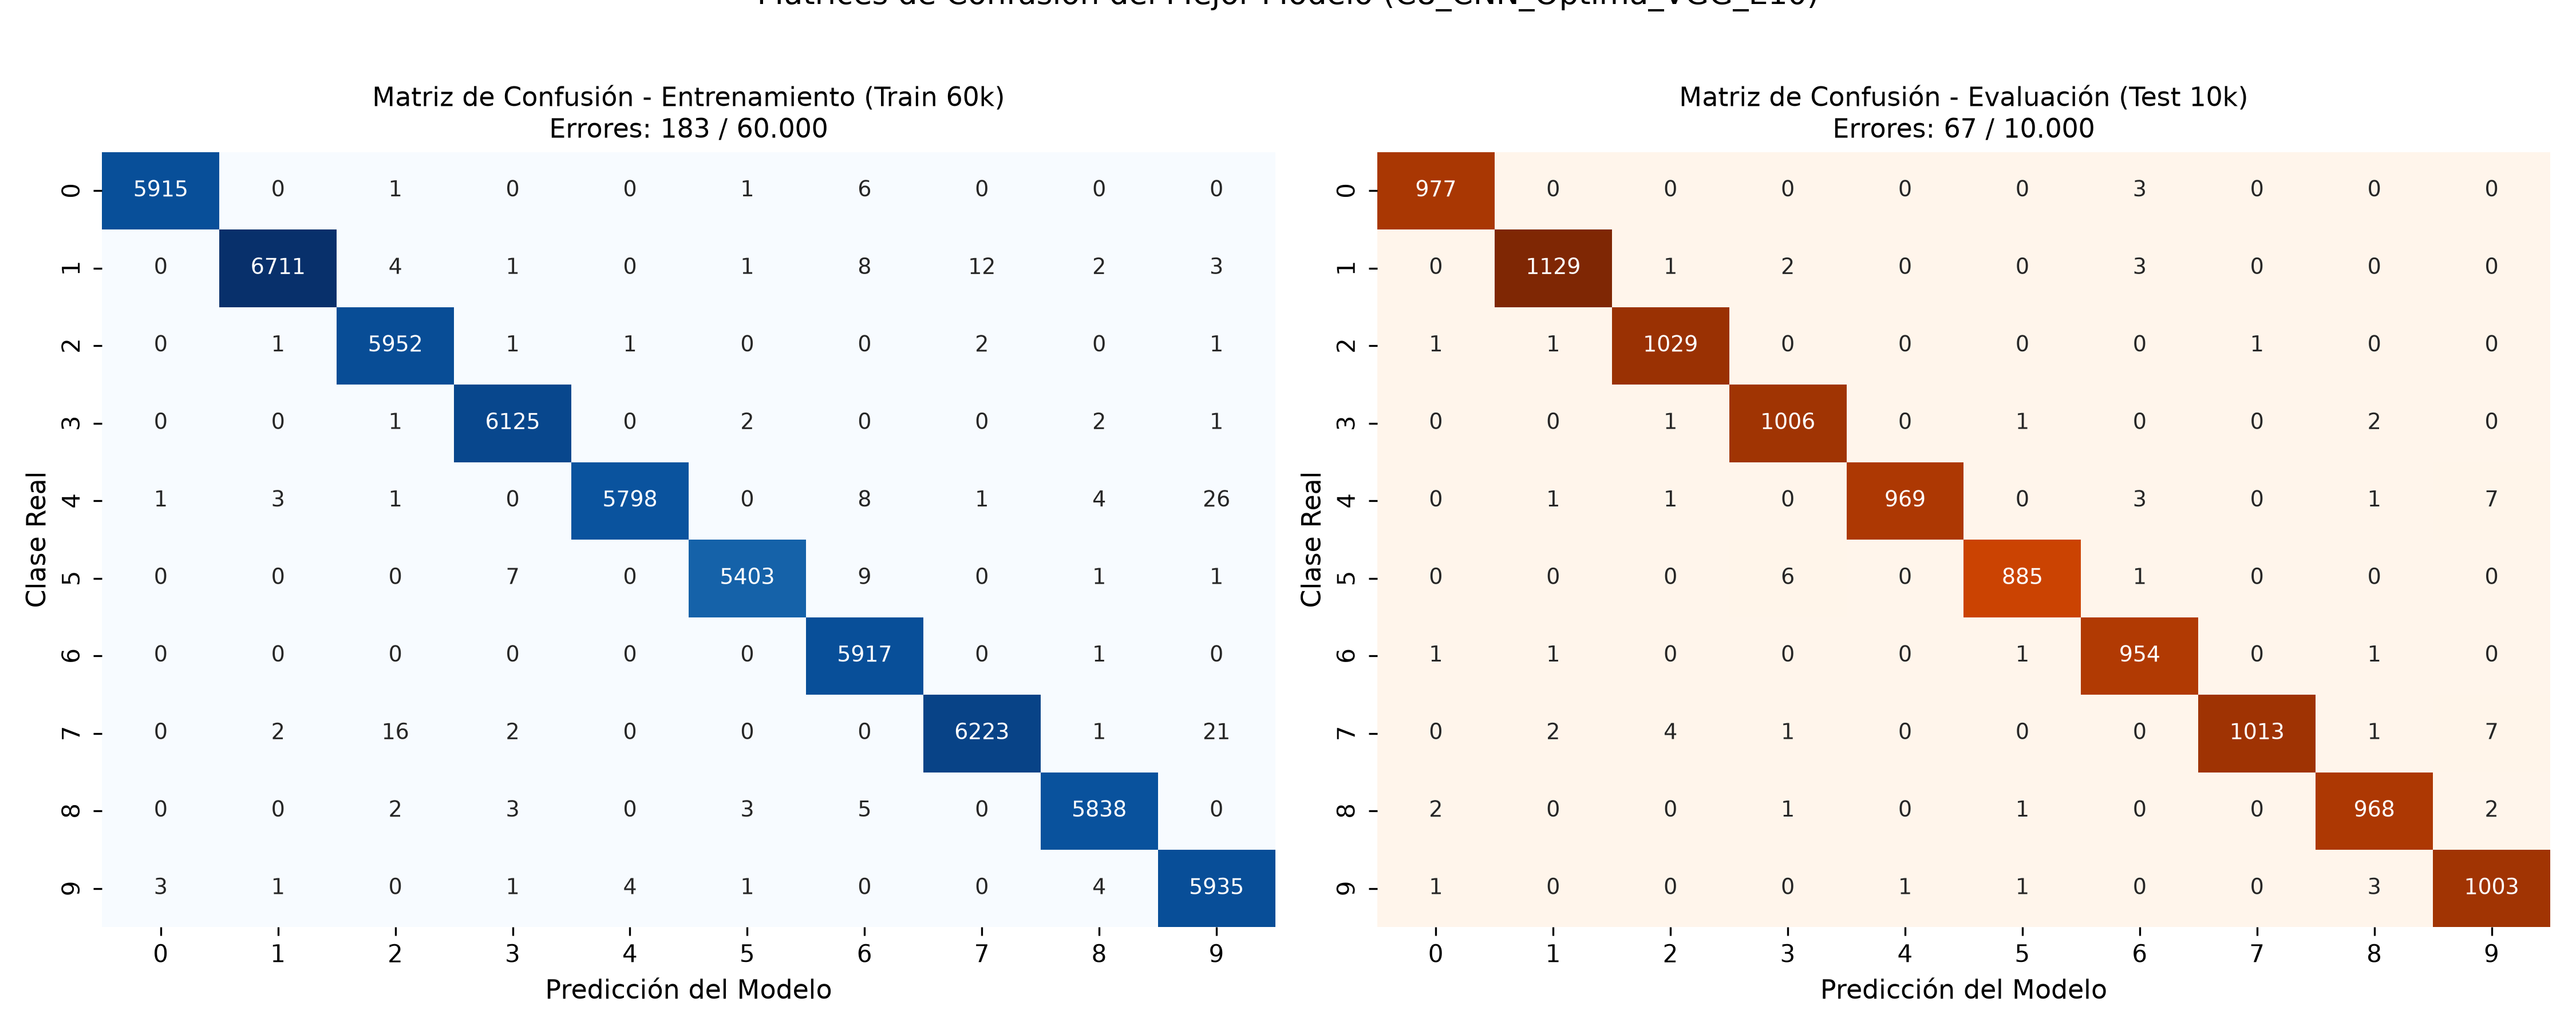

In [8]:
cm_train = confusion_matrix(y_train, mejor_preds_train)
cm_test = confusion_matrix(y_test, mejor_preds_test)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0], annot_kws={'size': 9})
axes[0].set_title(f'Matriz de Confusion - Entrenamiento (Train 60k)\nErrores: {int(np.sum(mejor_preds_train != y_train))} / 60.000', fontsize=11)
axes[0].set_xlabel('Prediccion del Modelo', fontsize=11)
axes[0].set_ylabel('Clase Real', fontsize=11)

sns.heatmap(cm_test, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=axes[1], annot_kws={'size': 9})
axes[1].set_title(f'Matriz de Confusion - Evaluacion (Test 10k)\nErrores: {int(np.sum(mejor_preds_test != y_test))} / 10.000', fontsize=11)
axes[1].set_xlabel('Prediccion del Modelo', fontsize=11)
axes[1].set_ylabel('Clase Real', fontsize=11)

plt.suptitle(f'Matrices de Confusion del Mejor Modelo ({mejor_id})', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


# Apartado 7, Justificación y razonamiento de los resultados

### 1. Superioridad Radical de la Red Convolucional frente al Perceptrón Multicapa (MLP)
* **Comparativa C1 vs C8**: El modelo de referencia C1 (MLP de una capa densa de 128 neuronas) alcanza un 97.43% de exactitud con **257 errores en test**. La arquitectura convolucional óptima C8 logra un **99.33% de exactitud en test** con tan solo **67 errores**.
* Esto representa una **reducción relativa del error del 73.93%** (se subsanan 190 imágenes mal clasificadas por el MLP). La causa teórica fundamental es que las capas convolucionales explotan el **sesgo inductivo espacial** (*spatial inductive bias*) y la compartición de pesos (*weight sharing*), preservando la estructura 2D de la imagen que el MLP destruye al aplanar la matriz a un vector unidimensional.

### 2. Eficiencia Paramétrica: El Rol Crítico de las Capas de Agrupamiento (Pooling)
* **Comparativa C2 vs C3 y C4**: En C2 (CNN sin pooling), conectar un mapa convolucional directamente a la capa densa provoca una explosión de **2.770.634 parámetros**, lo que satura la memoria y favorece el sobreajuste a coordenadas fijas de la imagen.
* Al incorporar **`MaxPooling2D`** en C3 y C4, las dimensiones espaciales se reducen drásticamente (de 28x28 a 5x5 tras dos etapas), disminuyendo el volumen de parámetros en más de un **91%** (de 2,77M a 225k parámetros) y mejorando simultáneamente la generalización de 98.28% a 98.78%.

### 3. Fundamentación Teórica del Diseño VGG: Convoluciones $3\times3$ en Cascada
* **Arquitecturas C7 y C8**: Apilar dos convoluciones consecutivas de $3\times3$ por bloque emula con exactitud el campo receptivo de un filtro grande de $5\times5$, pero reduce el número de operaciones y pesos en un **28%** ($2 \times 3^2 = 18$ pesos por canal frente a $5^2 = 25$).
* Asimismo, la introducción de dos activaciones no lineales ReLU intermedias en lugar de una proporciona a la red una mayor capacidad expresiva para discriminar detalles sutiles de los trazos manuscritos.

### 4. Regularización Mediante Dropout y Prevención de la Co-adaptación de Filtros
* **Comparativa C4 vs C5**: Añadir Dropout (0.25 tras convoluciones y 0.40 en la densa) reduce los errores de test de 122 a 83 con exactamente el mismo número de parámetros (225.034).
* El abandono estocástico desactiva aleatoriamente neuronas durante el entrenamiento, obligando a los filtros a aprender representaciones redundantes y robustas en lugar de memorizar detalles locales espurios.

### 5. Resumen Comparativo y Selección Definitiva
* **Mejor Configuración Identificada**: **`C8_CNN_Optima_VGG_E10`**.
* **Exactitud en Test**: **99.33%** (67 errores sobre 10.000 imágenes).
* **Exactitud en Train**: **99.70%** (183 errores sobre 60.000 imágenes).
* **Parámetros**: **271,210** pesos sinápticos.
* La ampliación del entrenamiento a 10 épocas en C8 permite alcanzar la convergencia óptima del gradiente, logrando el compromiso perfecto entre alta capacidad predictiva, eficiencia de cómputo y control del sobreajuste.

# Apartado 8, Guardado del mejor modelo en disco

La configuración que obtiene el mejor rendimiento global es **C8_CNN_Optima_VGG_E10 (CNN VGG-style Óptima (10 épocas))**, alcanzando un **99.33% de exactitud en test** (67 errores sobre 10.000) y un **99.70% de exactitud en train** (183 errores sobre 60.000). A continuación se almacena en disco en formato nativo `.keras`, se verifica su tamaño y se recarga para validar formalmente la integridad de sus predicciones.

In [9]:
ruta_modelo = 'mejor_modelo_cnn_mnist.keras'
mejor_modelo.save(ruta_modelo)
print(f'Modelo optimo guardado con exito en: {ruta_modelo}')
print(f'Tamano del fichero en disco: {os.path.getsize(ruta_modelo) / (1024*1024):.2f} MB')

modelo_recargado = tf.keras.models.load_model(ruta_modelo)
loss_rec, acc_rec = modelo_recargado.evaluate(x_test, y_test, verbose=0)
print(f'Verificacion del modelo recargado - Test Loss: {loss_rec:.4f} | Test Acc: {acc_rec*100:.2f}%')

preds_rec = np.argmax(modelo_recargado.predict(x_test, batch_size=256, verbose=0), axis=1)
err_rec = int(np.sum(preds_rec != y_test))
print(f'Errores cometidos por el modelo recargado: {err_rec} de {len(y_test)} muestras')
print('\nInforme de Clasificacion Estadistico por Digito:')
print(classification_report(y_test, preds_rec, digits=4))


Modelo optimo guardado con exito en: mejor_modelo_cnn_mnist.keras
Tamano del fichero en disco: 3.16 MB
Verificacion del modelo recargado - Test Loss: 0.0215 | Test Acc: 99.33%
Errores cometidos por el modelo recargado: 67 de 10000 muestras

Informe de Clasificacion Estadistico por Digito:
              precision    recall  f1-score   support

           0     0.9949    0.9969    0.9959       980
           1     0.9956    0.9947    0.9952      1135
           2     0.9932    0.9971    0.9952      1032
           3     0.9902    0.9960    0.9931      1010
           4     0.9990    0.9868    0.9928       982
           5     0.9955    0.9922    0.9938       892
           6     0.9896    0.9958    0.9927       958
           7     0.9990    0.9854    0.9922      1028
           8     0.9918    0.9938    0.9928       974
           9     0.9843    0.9941    0.9892      1009

    accuracy                         0.9933     10000
   macro avg     0.9933    0.9933    0.9933     10000
weight